In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("cleaned_wine_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (178, 14)

Column Names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins          

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
wine_class                      0
dtype: int64

Total Missing Values: 0


In [5]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


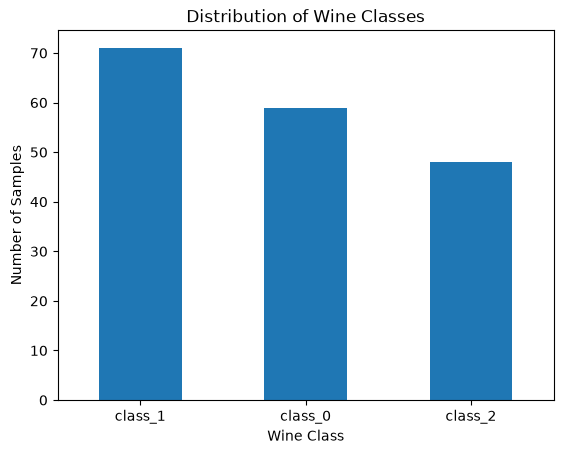

In [7]:
df["wine_class"].value_counts().plot(
    kind="bar",
    title="Distribution of Wine Classes"
)

plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

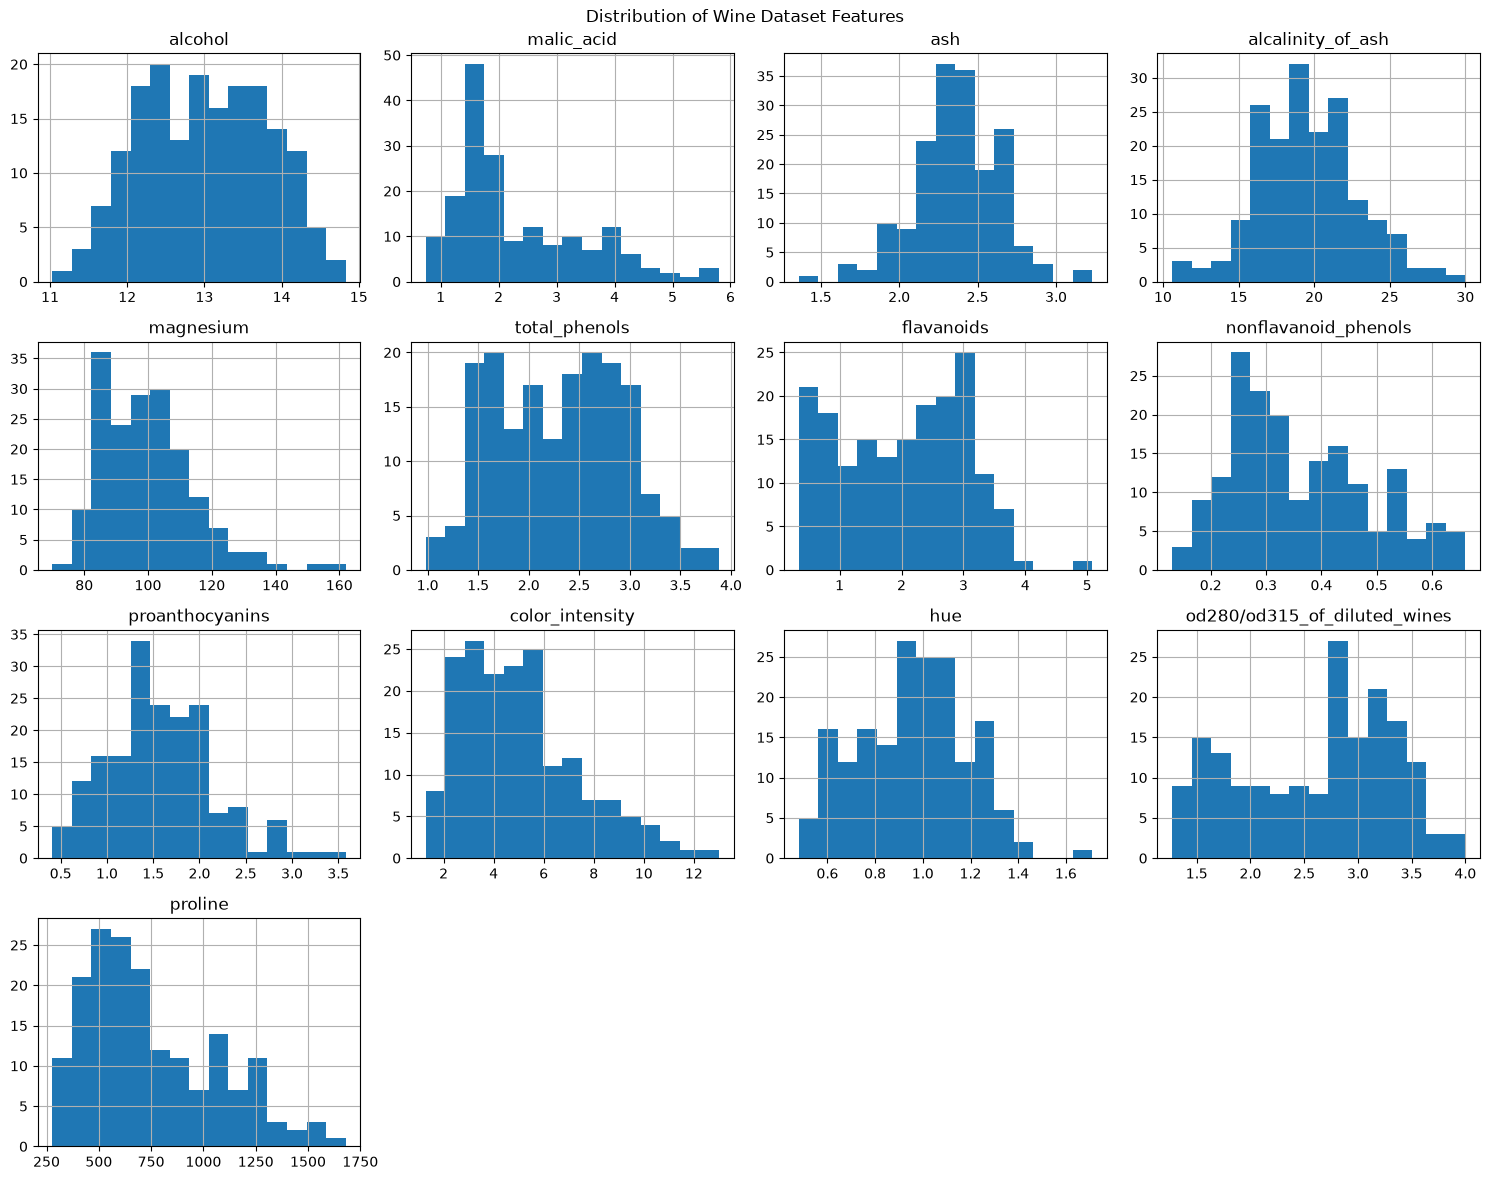

In [8]:
df.hist(figsize=(15, 12), bins=15)
plt.suptitle("Distribution of Wine Dataset Features")
plt.tight_layout()
plt.show()

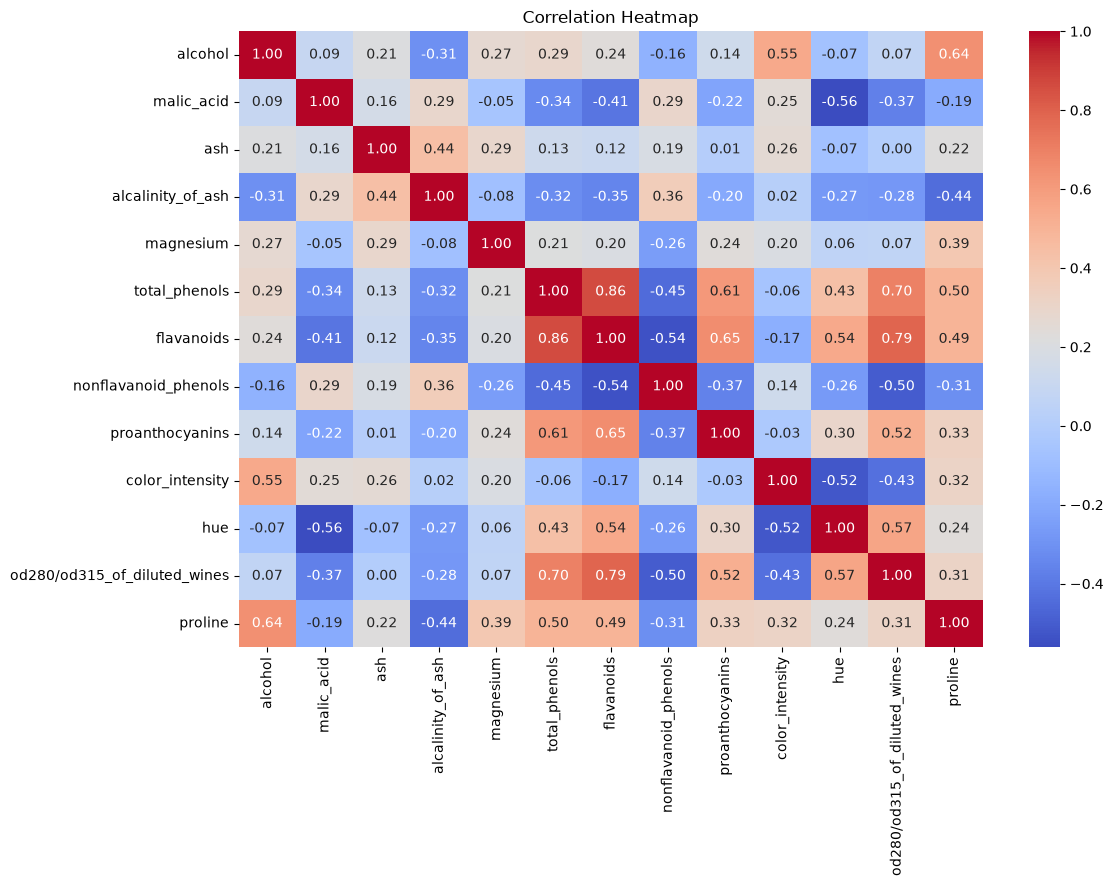

In [9]:
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [10]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

if "wine_class" in numeric_cols:
    numeric_cols.remove("wine_class")

outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Outlier Count": len(outliers),
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Outlier Count,Lower Bound,Upper Bound
0,alcohol,0,10.39000,15.65000
1,malic_acid,3,-0.61750,5.30250
2,ash,3,1.68875,3.07875
3,alcalinity_of_ash,4,10.75000,27.95000
4,magnesium,4,59.50000,135.50000
5,total_phenols,0,0.15625,4.38625
6,flavanoids,0,-1.30000,5.38000
7,nonflavanoid_phenols,0,0.01875,0.68875
8,proanthocyanins,2,0.20000,3.00000
9,color_intensity,4,-1.25000,10.67000


<Figure size 1200x600 with 0 Axes>

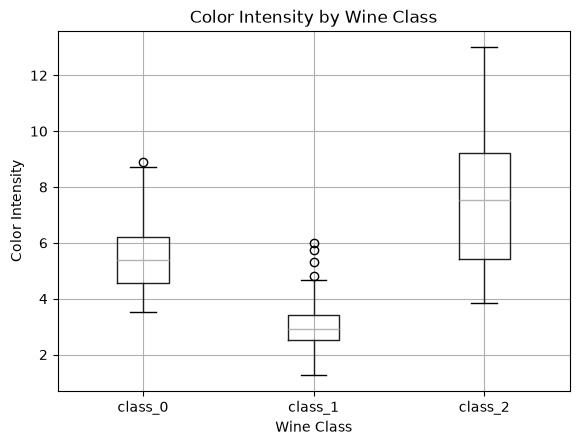

In [11]:
plt.figure(figsize=(12, 6))

df.boxplot(column="color_intensity", by="wine_class")

plt.title("Color Intensity by Wine Class")
plt.suptitle("")
plt.xlabel("Wine Class")
plt.ylabel("Color Intensity")

plt.show()

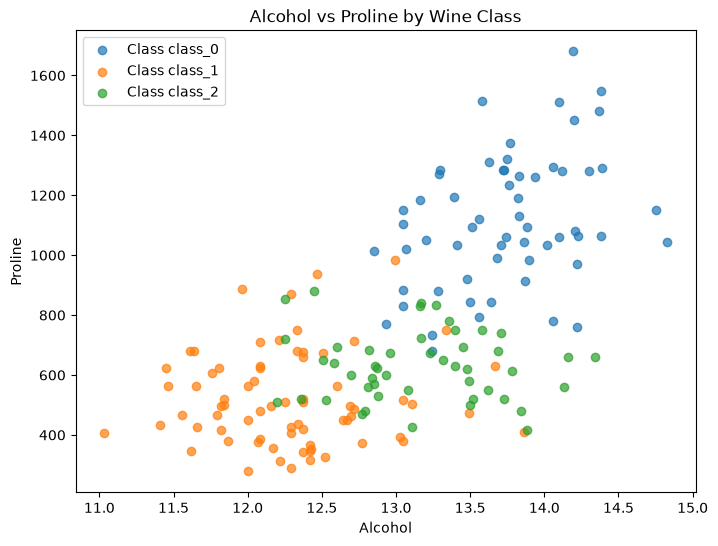

In [12]:
plt.figure(figsize=(8, 6))

for wine_class in sorted(df["wine_class"].unique()):
    subset = df[df["wine_class"] == wine_class]

    plt.scatter(
        subset["alcohol"],
        subset["proline"],
        label=f"Class {wine_class}",
        alpha=0.7
    )

plt.xlabel("Alcohol")
plt.ylabel("Proline")
plt.title("Alcohol vs Proline by Wine Class")
plt.legend()
plt.show()

In [13]:
class_summary = df.groupby("wine_class")["alcohol"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

class_summary

,count,mean,median,std,min,max
wine_class,,,,,,
class_0,59,13.744746,13.750,0.462125,12.85,14.83
class_1,71,12.278732,12.290,0.537964,11.03,13.86
class_2,48,13.153750,13.165,0.530241,12.20,14.34


In [14]:
from scipy.stats import f_oneway

groups = [
    df.loc[df["wine_class"] == cls, "alcohol"].dropna()
    for cls in sorted(df["wine_class"].unique())
]

f_statistic, p_value = f_oneway(*groups)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one class has a different mean alcohol level.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference in mean alcohol levels.")

F-statistic: 135.07762424279917
P-value: 3.319503795619574e-36
Reject H0: At least one class has a different mean alcohol level.


In [15]:
outlier_df.to_csv("week2_outlier_analysis.csv", index=False)
class_summary.to_csv("week2_class_summary.csv")

print("Week 2 analysis results saved successfully!")

Week 2 analysis results saved successfully!
